# 🏦 Projet 2 — Big Data : Santander Value Prediction (Hadoop HDFS + Spark)

**Données :** 4 459 lignes × 4 993 colonnes très creuses (~97 % de zéros). Cible : valeur de transaction. Métrique : **RMSLE**.

**Pipeline :** Stockage (local ou HDFS) → EDA distribuée (Spark SQL, MapReduce RDD) → Prétraitement → Transformation (log1p, stats par ligne, sélection RF sur le train uniquement) → MLlib (LR / RF / GBT + CrossValidator) → Évaluation → Soumission Kaggle

> ⚠️ Avant de lancer : accepter les règles de la compétition sur
> https://www.kaggle.com/competitions/santander-value-prediction-challenge/rules
> (sinon le téléchargement est refusé). Java 17 ou 21 doit être installé pour Spark 4.

## 0. Setup

In [1]:
%pip install -q pyspark pandas numpy matplotlib kaggle pyarrow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3.12 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, glob, zipfile, subprocess, shutil
import numpy as np, matplotlib.pyplot as plt

# ===== Choix du stockage =====
USE_HDFS = False   # True si le cluster Hadoop (docker-compose plus bas) tourne
LOCAL_DIR = "data/santander"
HDFS_DIR = "hdfs://namenode:9000/santander"

print("Java :", shutil.which("java") or "❌ non trouvé — installe un JDK (ex : Temurin 17)")

Java : /usr/bin/java


## 1. Data

In [3]:
os.makedirs(LOCAL_DIR, exist_ok=True)
if not os.path.exists(f"{LOCAL_DIR}/train.csv"):
    if not glob.glob(f"{LOCAL_DIR}/*.zip"):
        subprocess.run(["kaggle", "competitions", "download", "-c",
                        "santander-value-prediction-challenge", "-p", LOCAL_DIR])
    for z in glob.glob(f"{LOCAL_DIR}/*.zip"):
        zipfile.ZipFile(z).extractall(LOCAL_DIR)
    for z in glob.glob(f"{LOCAL_DIR}/*.zip"):          # zips imbriqués éventuels
        if z.endswith(("train.csv.zip", "test.csv.zip")):
            zipfile.ZipFile(z).extractall(LOCAL_DIR)
assert os.path.exists(f"{LOCAL_DIR}/train.csv"), (
    "❌ train.csv absent : télécharge les fichiers depuis l'onglet Data de la compétition "
    "et mets-les dans data/santander/")
print(os.listdir(LOCAL_DIR))

['sample_submission.csv', 'santander-value-prediction-challenge.zip', 'test.csv', 'train.csv']


### (Optionnel) Cluster Hadoop HDFS avec Docker
La cellule suivante écrit un `docker-compose.yml` (NameNode + DataNode). Ensuite, dans un terminal :
```bash
docker compose up -d
docker cp data/santander/train.csv namenode:/tmp/ && docker cp data/santander/test.csv namenode:/tmp/
docker exec namenode hdfs dfs -mkdir -p /santander
docker exec namenode hdfs dfs -put -f /tmp/train.csv /tmp/test.csv /santander/
docker exec namenode hdfs dfs -ls -h /santander
```
Interface web HDFS : http://localhost:9870. Pour lire depuis HDFS, Spark doit tourner dans le même réseau Docker (service `jupyter`), puis mettre `USE_HDFS = True`.

In [4]:
%%writefile docker-compose.yml
services:
  namenode:
    image: bde2020/hadoop-namenode:2.0.0-hadoop3.2.1-java8
    container_name: namenode
    ports: ["9870:9870", "9000:9000"]
    environment:
      - CLUSTER_NAME=bigdata
      - CORE_CONF_fs_defaultFS=hdfs://namenode:9000
    volumes: [namenode:/hadoop/dfs/name]
  datanode:
    image: bde2020/hadoop-datanode:2.0.0-hadoop3.2.1-java8
    container_name: datanode
    environment:
      - SERVICE_PRECONDITION=namenode:9870
      - CORE_CONF_fs_defaultFS=hdfs://namenode:9000
    volumes: [datanode:/hadoop/dfs/data]
  jupyter:
    image: quay.io/jupyter/pyspark-notebook
    ports: ["8888:8888", "4040:4040"]
    volumes: [./:/home/jovyan/work]
volumes: {namenode: {}, datanode: {}}

Overwriting docker-compose.yml


In [5]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("Santander-BigData")
         .master("local[4]")                                 # laisse des cœurs au driver / à l'OS
         .config("spark.driver.memory", "6g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.network.timeout", "800s")
         .config("spark.executor.heartbeatInterval", "60s")   # doit rester < network.timeout
         .config("spark.sql.debug.maxToStringFields", "100")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.sparkContext.setCheckpointDir("/tmp/spark-ckpt")       # coupe la lignée du GBT
DATA = HDFS_DIR if USE_HDFS else LOCAL_DIR
print("Spark", spark.version, "| source :", DATA, "| UI : http://localhost:4040")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/18 16:38:46 WARN Utils: Your hostname, DESKTOP-M16PT3A, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/18 16:38:46 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 16:38:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.3.0 | source : data/santander | UI : http://localhost:4040


In [6]:
train = spark.read.csv(f"{DATA}/train.csv", header=True, inferSchema=True)
test  = spark.read.csv(f"{DATA}/test.csv",  header=True, inferSchema=True)
feat_cols = [c for c in train.columns if c not in ("ID", "target")]
n_train = train.count()
print(f"train : {n_train} x {len(train.columns)} | test : {test.count()} x {len(test.columns)}")
print("Partitions :", train.rdd.getNumPartitions())

[Stage 7:====================================>                      (5 + 3) / 8]

train : 4459 x 4993 | test : 49342 x 4992
Partitions : 4


## 2. EDA distribuée

+----+-------+---------+---------+-----+
|   n|    min|      avg|   median|  max|
+----+-------+---------+---------+-----+
|4459|30000.0|5944923.0|2260000.0|4.0E7|
+----+-------+---------+---------+-----+



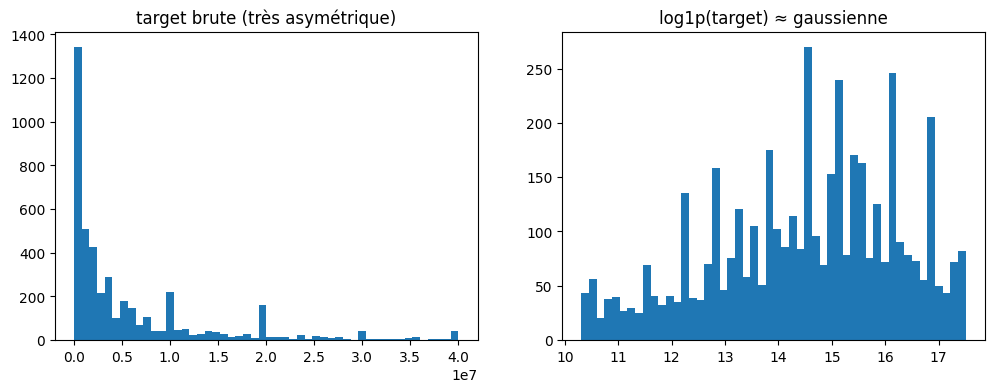

In [7]:
train.createOrReplaceTempView("train")
spark.sql('''
  SELECT COUNT(*) AS n, ROUND(MIN(target)) AS min, ROUND(AVG(target)) AS avg,
         ROUND(PERCENTILE_APPROX(target, 0.5)) AS median, ROUND(MAX(target)) AS max
  FROM train''').show()

t = train.select("target").toPandas()["target"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(t, bins=50); ax[0].set_title("target brute (très asymétrique)")
ax[1].hist(np.log1p(t), bins=50); ax[1].set_title("log1p(target) ≈ gaussienne")
plt.show()

Colonnes constantes (toujours 0) : 256
Densité globale : 3.15%


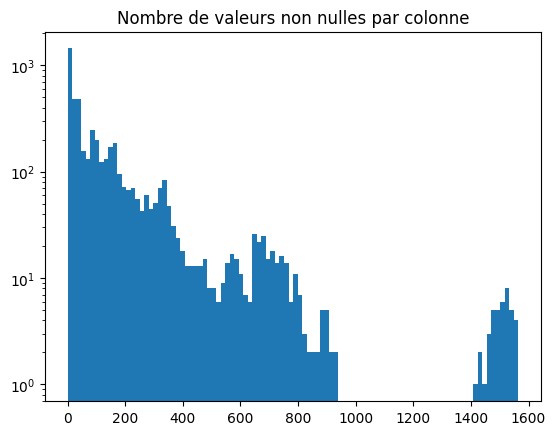

In [8]:
# Non-zéros par colonne en UNE seule passe distribuée
nz = train.select([F.sum((F.col(c) != 0).cast("int")).alias(c) for c in feat_cols]).first().asDict()
nz = {k: (v or 0) for k, v in nz.items()}
const_cols = [c for c, v in nz.items() if v == 0]
print(f"Colonnes constantes (toujours 0) : {len(const_cols)}")
print(f"Densité globale : {sum(nz.values()) / (len(feat_cols) * n_train):.2%}")
plt.hist(list(nz.values()), bins=100, log=True)
plt.title("Nombre de valeurs non nulles par colonne"); plt.show()

In [9]:
# Paradigme MapReduce avec un RDD : compter les non-zéros par colonne
cols_b = spark.sparkContext.broadcast(feat_cols)
top_cols = (train.select(feat_cols).rdd
            .flatMap(lambda row: [(c, 1) for c, v in zip(cols_b.value, row) if v != 0])   # MAP
            .reduceByKey(lambda a, b: a + b)                                               # REDUCE
            .takeOrdered(10, key=lambda kv: -kv[1]))
top_cols

[('c5a231d81', 1565),
 ('0ff32eb98', 1565),
 ('91f701ba2', 1560),
 ('c47340d97', 1555),
 ('0572565c2', 1547),
 ('adb64ff71', 1547),
 ('f190486d6', 1544),
 ('5c6487af1', 1539),
 ('e176a204a', 1535),
 ('6619d81fc', 1533)]

## 3. Prétraitement + 4. Transformation

In [10]:
keep = [c for c in feat_cols if c not in const_cols]

def transform(df, with_target=True):
    cols = [F.col("ID")] + [F.log1p(F.col(c).cast("double")).alias(c) for c in keep]
    if with_target:
        cols.append(F.log1p(F.col("target").cast("double")).alias("label"))
    return df.select(*cols)

STATS = ["nz_count", "nz_sum", "nz_mean", "nz_max", "nz_min"]

def row_stats(df):
    df = df.withColumn("nz", F.filter(F.array(*[F.col(c) for c in keep]), lambda x: x != 0))
    return (df.withColumn("nz_count", F.size("nz").cast("double"))
              .withColumn("nz_sum", F.aggregate("nz", F.lit(0.0), lambda acc, x: acc + x))
              .withColumn("nz_mean", F.when(F.col("nz_count") > 0, F.col("nz_sum") / F.col("nz_count")).otherwise(0.0))
              .withColumn("nz_max", F.coalesce(F.array_max("nz"), F.lit(0.0)))
              .withColumn("nz_min", F.coalesce(F.array_min("nz"), F.lit(0.0)))
              .drop("nz"))

tr = row_stats(transform(train)).cache()
te = row_stats(transform(test, with_target=False)).cache()
tr.count()   # matérialise le cache
print("Colonnes gardées :", len(keep))
tr.select(STATS + ["label"]).describe().show()

Colonnes gardées : 4735
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|          nz_count|            nz_sum|           nz_mean|            nz_max|            nz_min|             label|
+-------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|              4459|              4459|              4459|              4459|              4459|              4459|
|   mean|157.01031621439785|2247.8575389367043|14.414275002300732|17.326075186216517| 11.06051423965674|14.490239292748607|
| stddev| 212.0855409953595|3048.5361824901806|1.5158298880786953| 1.600266776495178| 2.496607666981934|1.7509468324687072|
|    min|               1.0| 8.294299608857235|  8.04745509593011| 8.294299608857235| 3.970291913552122|10.308985993422082|
|    max|            1989.0|29398.195462988595|19.806975107572256|22.260563071817792|19.806975107572256| 17.

In [11]:
# Split train / validation AVANT toute sélection (évite la fuite de données)
# Split déterministe par hash de l'ID : ~80 % train / ~20 % validation
is_val = (F.abs(F.hash("ID")) % 5 == 0)
tr_fit = tr.filter(~is_val)
tr_val = tr.filter(is_val)
print("train :", tr_fit.count(), "| validation :", tr_val.count())

# Sélection de features : importance d'une Random Forest (train uniquement) -> top 500
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor

va_all = VectorAssembler(inputCols=keep + STATS, outputCol="features")
rf_sel = RandomForestRegressor(numTrees=100, maxDepth=8, featureSubsetStrategy="sqrt", seed=42)
rf_model = rf_sel.fit(va_all.transform(tr_fit).select("features", "label"))

imp = sorted(zip(keep + STATS, rf_model.featureImportances.toArray()), key=lambda x: -x[1])
TOP = [c for c, _ in imp[:500]]
print("Top 15 :")
for c, v in imp[:15]:
    print(f"  {c:12s} {v:.4f}")

train : 3529 | validation : 930


Top 15 :
  nz_mean      0.0561
  nz_min       0.0300
  nz_max       0.0293
  f190486d6    0.0269
  eeb9cd3aa    0.0106
  58e2e02e6    0.0102
  f74e8f13d    0.0100
  6eef030c1    0.0098
  b43a7cfd5    0.0086
  15ace8c9f    0.0081
  9fd594eec    0.0079
  58232a6fb    0.0076
  fb0f5dbfe    0.0069
  5c6487af1    0.0069
  adb64ff71    0.0068


## 5. Machine Learning (Spark MLlib)

In [12]:
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

FEATS = list(dict.fromkeys(TOP + STATS))
va = VectorAssembler(inputCols=FEATS, outputCol="features")
# Peu de lignes -> peu de partitions (sinon des milliers de mini-stages pour les arbres)
train_df = va.transform(tr_fit).select("ID", "features", "label").coalesce(4).cache()
val_df   = va.transform(tr_val).select("ID", "features", "label").coalesce(2).cache()
print("train_df :", train_df.count(), "| val_df :", val_df.count())

ev = RegressionEvaluator(labelCol="label", metricName="rmse")   # RMSE sur log1p = RMSLE
models = {
    "LinearRegression": LinearRegression(regParam=0.1, elasticNetParam=0.5),
    "RandomForest": RandomForestRegressor(numTrees=200, maxDepth=10, seed=42),
    "GBT": GBTRegressor(maxIter=80, maxDepth=5, stepSize=0.05, seed=42),
}
scores = {}
for name, m in models.items():
    scores[name] = ev.evaluate(m.fit(train_df).transform(val_df))
    print(f"{name:18s} RMSLE validation = {scores[name]:.4f}")

train_df : 3529 | val_df : 930


LinearRegression   RMSLE validation = 1.4496


RandomForest       RMSLE validation = 1.3684


GBT                RMSLE validation = 1.4300


In [13]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

gbt = GBTRegressor(seed=42, maxIter=60, subsamplingRate=0.7,
                   featureSubsetStrategy="sqrt", minInstancesPerNode=5)
grid = (ParamGridBuilder()
        .addGrid(gbt.maxDepth, [3, 5])
        .addGrid(gbt.stepSize, [0.03, 0.1])
        .build())
cv = CrossValidator(estimator=gbt, estimatorParamMaps=grid, evaluator=ev,
                    numFolds=3, parallelism=1, seed=42)
cv_model = cv.fit(train_df)
best = cv_model.bestModel
print("Meilleurs params : maxDepth =", best.getMaxDepth(), "| stepSize =", best.getStepSize())
print("RMSLE CV :", [round(x, 4) for x in cv_model.avgMetrics])
scores["GBT tuned (CV)"] = ev.evaluate(best.transform(val_df))
print("RMSLE validation :", round(scores["GBT tuned (CV)"], 4))

Meilleurs params : maxDepth = 3 | stepSize = 0.1
RMSLE CV : [np.float64(1.4681), np.float64(1.4608), np.float64(1.4699), np.float64(1.4852)]
RMSLE validation : 1.4438


## 6. Évaluation

,RMSLE
RandomForest,1.368425
GBT,1.430030
GBT tuned (CV),1.443834
LinearRegression,1.449554


Meilleur modèle en validation : RandomForest


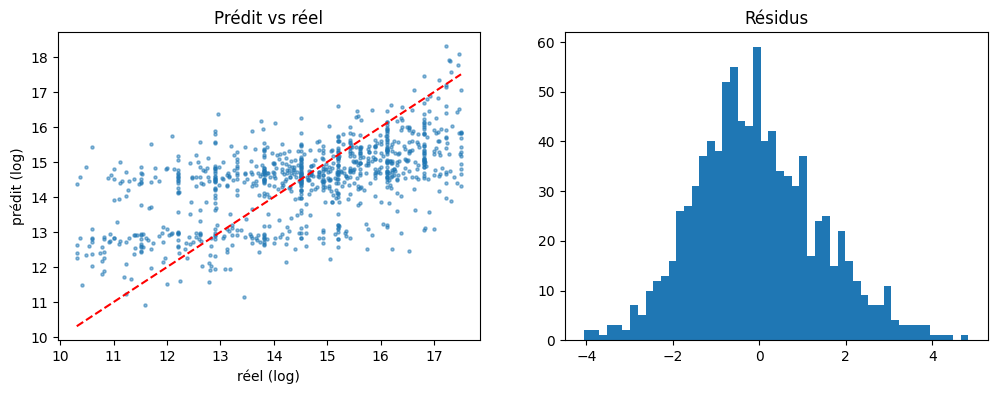

,feature,importance
0,nz_mean,0.197088
1,nz_min,0.059718
2,nz_count,0.021902
3,nz_max,0.021174
4,58e2e02e6,0.016216
5,041c5d0c9,0.014544
6,26ab20ff9,0.014200
7,f190486d6,0.013229
8,87ffda550,0.012944
9,3e1100230,0.012447


In [14]:
import pandas as pd
ranking = pd.Series(scores, name="RMSLE").sort_values()
display(ranking.to_frame())
print("Meilleur modèle en validation :", ranking.index[0])

pv = best.transform(val_df).select("label", "prediction").toPandas()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(pv.label, pv.prediction, s=5, alpha=.5)
lims = [pv.label.min(), pv.label.max()]
ax[0].plot(lims, lims, "r--"); ax[0].set_xlabel("réel (log)"); ax[0].set_ylabel("prédit (log)")
ax[0].set_title("Prédit vs réel")
ax[1].hist(pv.prediction - pv.label, bins=50); ax[1].set_title("Résidus")
plt.show()

fi = sorted(zip(FEATS, best.featureImportances.toArray()), key=lambda x: -x[1])[:15]
pd.DataFrame(fi, columns=["feature", "importance"])

## 7. Prédiction test, soumission Kaggle et sauvegarde du modèle

In [16]:
# Soumission : 49 342 lignes, on passe par pandas (pas besoin de Hadoop pour écrire)
sub = (best.transform(va.transform(te))
           .select("ID", F.expm1("prediction").alias("target")))
sub_pd = sub.toPandas()
sub_pd.to_csv("submission.csv", index=False)

# Modèle : à enregistrer sur le disque Linux de WSL, pas sur /mnt/c
model_path = os.path.expanduser("~/models/gbt_best")
best.write().overwrite().save(model_path)

print("✅ submission.csv prêt à soumettre sur Kaggle |", sub_pd.shape, "| modèle :", model_path)
print(sub_pd.head())
print("min/max target :", sub_pd.target.min(), sub_pd.target.max())

✅ submission.csv prêt à soumettre sur Kaggle | (49342, 2) | modèle : /home/karim/models/gbt_best
          ID        target
0  000137c73  2.109230e+06
1  00021489f  2.505661e+06
2  0004d7953  2.843955e+06
3  00056a333  3.382064e+06
4  00056d8eb  2.670045e+06
min/max target : 62995.872257875475 163431756.41384545


**Conclusion :** HDFS sert au stockage distribué. Spark SQL et les DataFrames font l'EDA sur ~5 000 colonnes en une passe, et le RDD illustre MapReduce.
La transformation `log1p`, les statistiques par ligne et la sélection par Random Forest (faite sur le train uniquement, après le split) réduisent la dimension (≈4 700 → 505 features).
Les modèles sont comparés sur la même validation (RMSLE) ; le classement final est affiché en section 6. Sur ce jeu très creux et de petite taille (4 459 lignes), les modèles à arbres peu profonds et régularisés sont les plus adaptés : le GBT n'est le meilleur que si le tableau de la section 6 le confirme.

In [ ]:
spark.stop()